# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**
- **Dataset name:** Digital Marketing Metrics & KPIs to Measure.
- **Source:** Kaggle.
- **URL:** https://www.kaggle.com/datasets/sinderpreet/analyze-the-marketing-spending
- **Why I chose it:** It contains dates, campaign categories,
  impressions, advertising costs, clicks, orders and revenue.
  These columns support the main analyses required by the lab.
- **What is one row?** One campaign on one day in the original
  file. After aggregation, one channel category on one day.
- **Groups:** Social, search, influencer and media.
- **Period:** 1–28 February 2021.
- **Size:** 308 original rows; 112 prepared rows.
- **Source limitation:** The original business source, real or
  synthetic status and currency were not independently verified.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [2]:
# TODO: load your dataset
# Load the original dataset and standardize column names
CSV_PATH = "Marketing.csv"

COLUMN_MAP = {
    "c_date": "date",
    "category": "channel",
    "mark_spent": "cost",
    "orders": "conversions",
}

raw = pd.read_csv(CSV_PATH).rename(columns=COLUMN_MAP)

print("Dataset shape:", raw.shape)
print("\nColumn types:")
print(raw.dtypes)

display(raw.head())

Dataset shape: (308, 11)

Column types:
id                 int64
date                 str
campaign_name        str
channel              str
campaign_id        int64
impressions        int64
cost             float64
clicks             int64
leads              int64
conversions        int64
revenue          float64
dtype: object


,id,date,campaign_name,channel,campaign_id,impressions,cost,clicks,leads,conversions,revenue
0,1,2021-02-01,facebook_tier1,social,349043,148263,7307.37,1210,13,1,4981.0
1,2,2021-02-01,facebOOK_tier2,social,348934,220688,16300.20,1640,48,3,14962.0
2,3,2021-02-01,google_hot,search,89459845,22850,5221.60,457,9,1,7981.0
3,4,2021-02-01,google_wide,search,127823,147038,6037.00,1196,24,1,2114.0
4,5,2021-02-01,youtube_blogger,influencer,10934,225800,29962.20,2258,49,10,84490.0


In [3]:
# TODO: clean the data
# Prepare and validate campaign-level data
df = raw.copy()
num_cols = ["impressions", "clicks", "conversions", "cost", "revenue"]

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["channel"] = df["channel"].str.strip().str.lower()

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values:")
print(df[["date", "channel"] + num_cols].isna().sum())

invalid = (
    df[["date", "channel"] + num_cols].isna().any(axis=1)
    | (df[num_cols] < 0).any(axis=1)
    | (df["clicks"] > df["impressions"])
    | (df["conversions"] > df["clicks"])
)

print("\nInvalid rows:", invalid.sum())

# Stop if validation fails, so we can investigate
assert not invalid.any(), "Review invalid rows before continuing."
assert not df.duplicated(["date", "campaign_id"]).any(), (
    "Duplicate campaign-date rows found."
)

# Sum campaigns within each channel and day
df = (
    df.groupby(["date", "channel"], as_index=False)[num_cols]
    .sum()
    .sort_values(["channel", "date"])
    .reset_index(drop=True)
)

print("\nPrepared shape:", df.shape)
print("\nDaily rows per channel:")
print(df["channel"].value_counts())
print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("\nDays with zero conversions:",
      (df["conversions"] == 0).sum())

df.to_csv(OUT / "marketing_data.csv", index=False)
print("\nSaved: outputs/marketing_data.csv")

display(df.head())

Missing values:
date           0
channel        0
impressions    0
clicks         0
conversions    0
cost           0
revenue        0
dtype: int64

Invalid rows: 0

Prepared shape: (112, 7)

Daily rows per channel:
channel
influencer    28
media         28
search        28
social        28
Name: count, dtype: int64

Date range: 2021-02-01 00:00:00 to 2021-02-28 00:00:00

Days with zero conversions: 2

Saved: outputs/marketing_data.csv


,date,channel,impressions,clicks,conversions,cost,revenue
0,2021-02-01,influencer,346236,3756,17,53566.3,123571.0
1,2021-02-02,influencer,748800,7488,20,56220.2,163607.0
2,2021-02-03,influencer,1702613,22499,142,383677.0,1026530.0
3,2021-02-04,influencer,3319855,29986,127,334542.0,849500.0
4,2021-02-05,influencer,4118411,37510,154,479048.7,1213046.0


###✍️ Transformations I made

- Renamed columns: c_date → date, category → channel,
  mark_spent → cost, and orders → conversions.
- Converted dates to datetime and checked numeric columns.
- Standardized channel names.
- Checked missing values, negative values, invalid counts,
  and duplicate campaign-date records. No invalid rows were found.
- Grouped campaigns by date and channel, adding their counts and amounts.
- The prepared dataset has 112 rows: four channels with 28 days each.
- The period is 1–28 February 2021.
- Kept two channel-day records with zero conversions.
  Their daily CPA will be undefined, not zero.
- Saved the prepared data as outputs/marketing_data.csv.

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [4]:
# TODO: totals per channel, then the metrics
# Calculate monthly totals and metrics by channel
agg = df.groupby("channel")[num_cols].sum()

agg["CTR"] = agg["clicks"] / agg["impressions"].where(
    agg["impressions"] > 0
)
agg["conv_rate"] = agg["conversions"] / agg["clicks"].where(
    agg["clicks"] > 0
)
agg["CPA"] = agg["cost"] / agg["conversions"].where(
    agg["conversions"] > 0
)
agg["ROAS"] = agg["revenue"] / agg["cost"].where(
    agg["cost"] > 0
)
agg["profit"] = agg["revenue"] - agg["cost"]
agg["profit_margin"] = agg["profit"] / agg["revenue"].where(
    agg["revenue"] > 0
)

agg = agg.replace([np.inf, -np.inf], np.nan)
agg.to_csv(OUT / "channel_summary.csv")

display(agg.round(4))

,impressions,clicks,conversions,cost,revenue,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
influencer,77800724,749973,3014,8305304.08,21119887.0,0.0096,0.0040,2755.5753,2.5429,12814582.92,0.6068
media,1068337427,420003,1566,5026674.76,6152960.0,0.0004,0.0037,3209.8817,1.2241,1126285.24,0.1830
search,72298252,330054,828,3460400.07,3705065.0,0.0046,0.0025,4179.2271,1.0707,244664.93,0.0660
social,359285996,1499889,2635,13798500.91,11911454.0,0.0042,0.0018,5236.6227,0.8632,-1887046.91,-0.1584


💡 **Hint: watch out for zero-cost channels** (e.g. SEO, organic). ROAS becomes infinite, and CPA becomes **$0**, which would make the channel look like the best one. Use `.where(agg.cost > 0)` to give them no CPA.

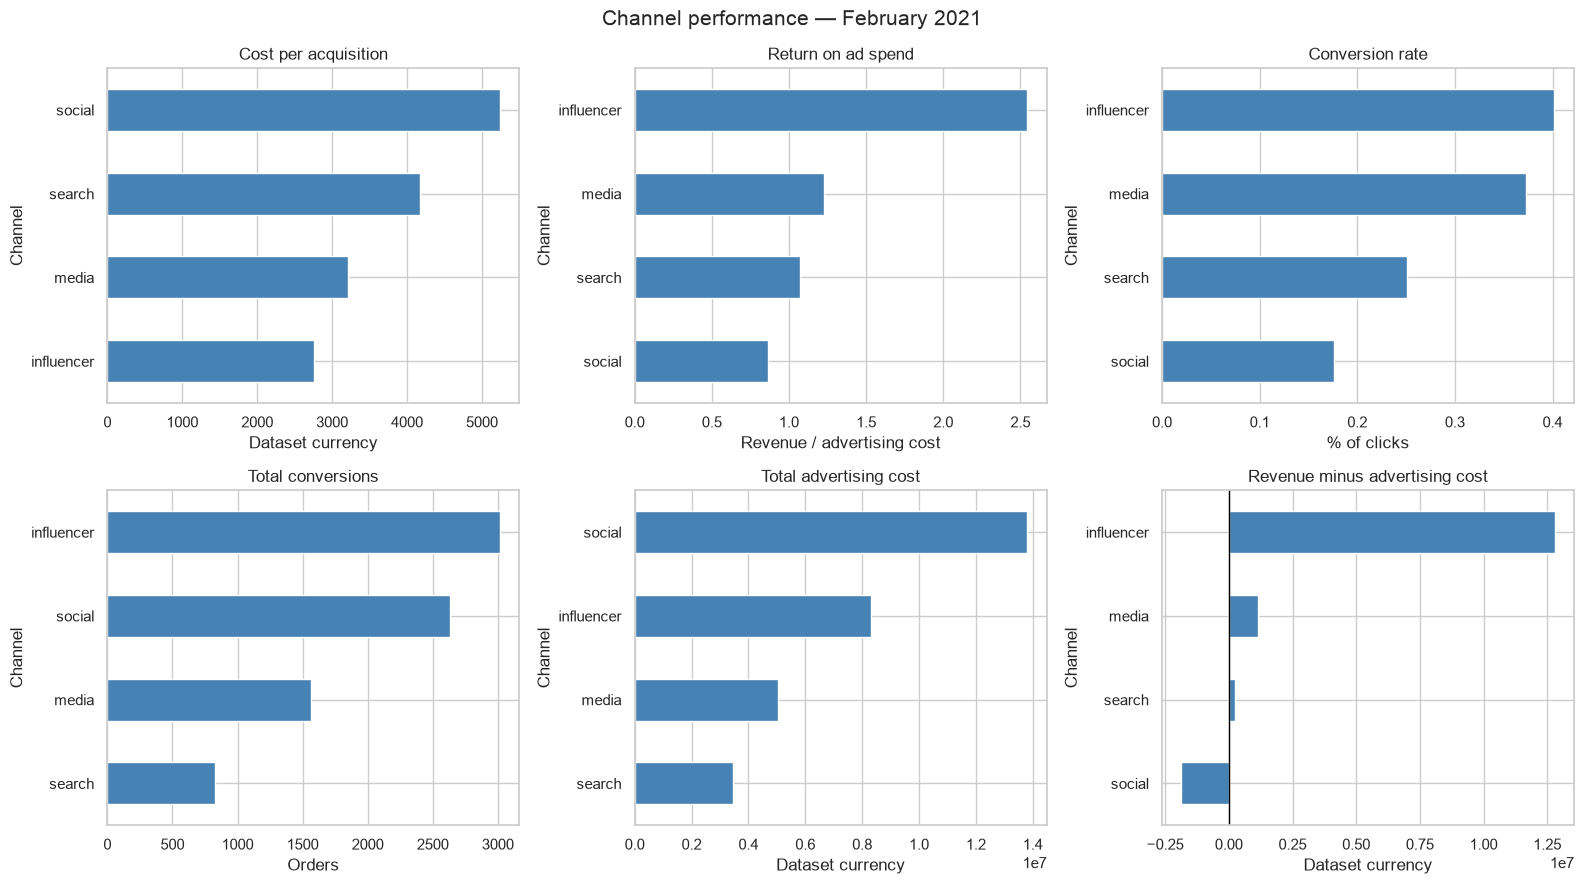

In [5]:
# TODO: 2x3 grid of horizontal bar charts: CPA, ROAS, conversion rate, conversions, cost, profit
# Plot monthly performance by channel
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

plots = [
    ("CPA", "Cost per acquisition", "Dataset currency"),
    ("ROAS", "Return on ad spend", "Revenue / advertising cost"),
    ("conv_rate", "Conversion rate", "% of clicks"),
    ("conversions", "Total conversions", "Orders"),
    ("cost", "Total advertising cost", "Dataset currency"),
    ("profit", "Revenue minus advertising cost", "Dataset currency"),
]

for ax, (metric, title, xlabel) in zip(axes.flat, plots):
    values = agg[metric].sort_values()

    if metric == "conv_rate":
        values = values * 100

    values.plot.barh(ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Channel")

    if metric == "profit":
        ax.axvline(0, color="black", linewidth=1)

fig.suptitle("Channel performance — February 2021", fontsize=15)
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=150)
plt.show()

Days with undefined CPA:
channel
influencer    0
media         1
search        1
social        0
Name: CPA, dtype: int64


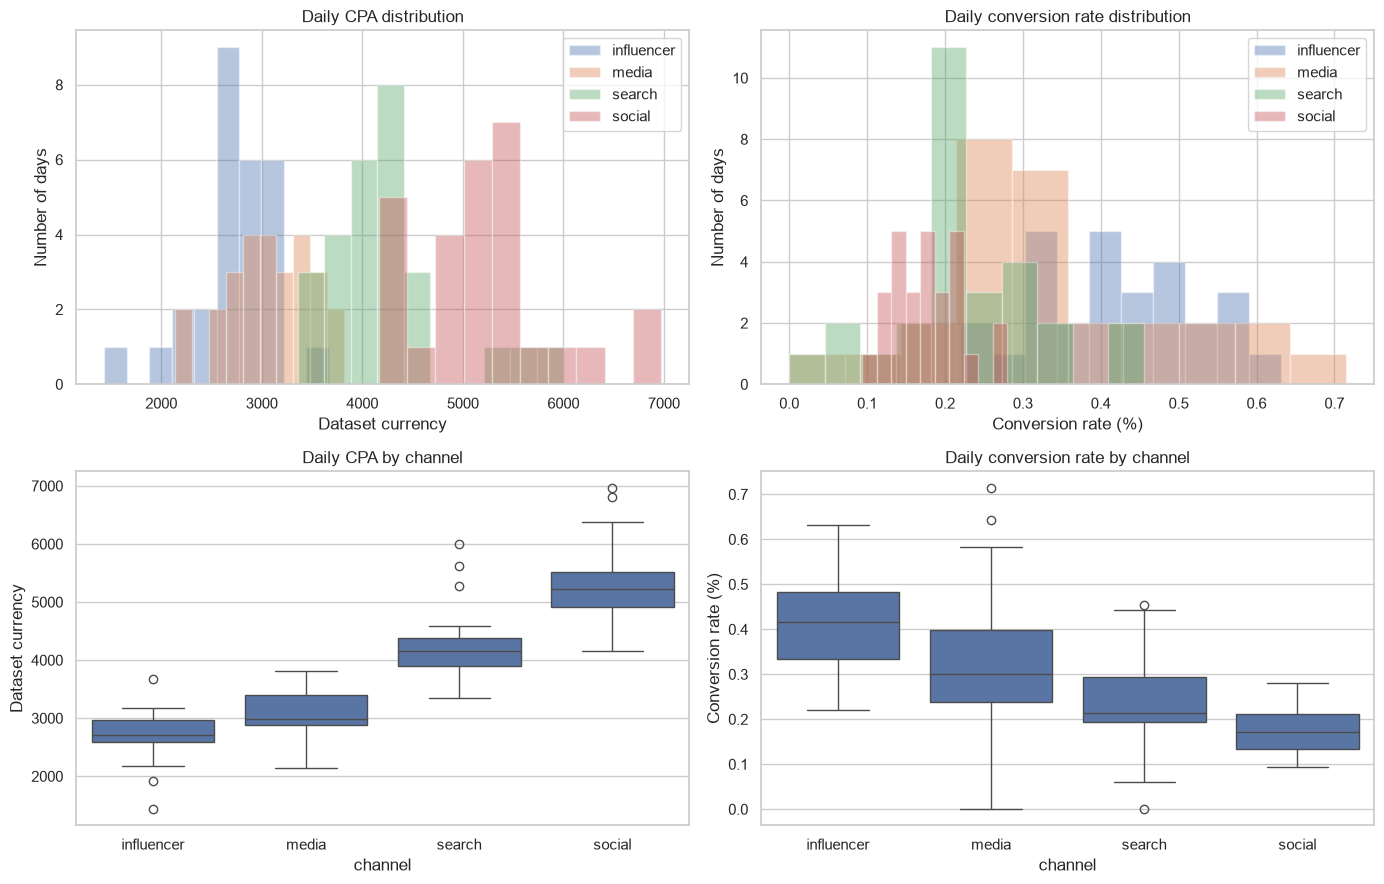

,valid_days,mean,std,CV
channel,,,,
influencer,28,2716.159,426.644,0.157
media,27,3071.595,424.736,0.138
search,27,4210.971,600.232,0.143
social,28,5242.341,713.881,0.136


In [6]:
# TODO: per-day (or per-week) metrics -> these give the SPREAD you need for t-tests
# Daily metrics: zero conversions give an undefined CPA
df["CPA"] = df["cost"] / df["conversions"].where(
    df["conversions"] > 0
)
df["conv_rate"] = df["conversions"] / df["clicks"].where(
    df["clicks"] > 0
)
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df["cost"] > 0].copy()

# Show missing CPA values explicitly
print("Days with undefined CPA:")
print(df.groupby("channel")["CPA"].apply(lambda x: x.isna().sum()))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
channels = sorted(df["channel"].unique())

for channel in channels:
    subset = df[df["channel"] == channel]

    axes[0, 0].hist(
        subset["CPA"].dropna(),
        bins=10, alpha=0.4, label=channel
    )
    axes[0, 1].hist(
        subset["conv_rate"].dropna() * 100,
        bins=10, alpha=0.4, label=channel
    )

axes[0, 0].set_title("Daily CPA distribution")
axes[0, 0].set_xlabel("Dataset currency")
axes[0, 1].set_title("Daily conversion rate distribution")
axes[0, 1].set_xlabel("Conversion rate (%)")

for ax in axes[0]:
    ax.set_ylabel("Number of days")
    ax.legend()

sns.boxplot(
    data=df, x="channel", y="CPA",
    order=channels, ax=axes[1, 0]
)
axes[1, 0].set_title("Daily CPA by channel")
axes[1, 0].set_ylabel("Dataset currency")

sns.boxplot(
    data=df.assign(conv_rate_pct=df["conv_rate"] * 100),
    x="channel", y="conv_rate_pct",
    order=channels, ax=axes[1, 1]
)
axes[1, 1].set_title("Daily conversion rate by channel")
axes[1, 1].set_ylabel("Conversion rate (%)")

plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=150)
plt.show()

# CPA statistics cover only days with at least one conversion
variability = df.groupby("channel")["CPA"].agg(
    valid_days="count",
    mean="mean",
    std="std"
)
variability["CV"] = variability["std"] / variability["mean"]
variability.to_csv(OUT / "channel_variability.csv")

display(variability.round(3))

###✍️ Key insights:

- Influencer has the lowest monthly CPA (2,755.58) and the highest
  ROAS (2.54) and monthly conversion rate.
- Social has the highest monthly CPA (5,236.62) and a ROAS below 1.
- Influencer has the highest relative daily CPA variability
  (CV = 15.7%). Social has the highest standard deviation.
- Influencer and media show some overlap in daily CPA.
- The box plots show possible outliers. They were kept.
- Media and search each have one day with zero conversions.
  Their mean daily CPA excludes that day, but monthly CPA includes
  all advertising costs.
- These findings are descriptive. Statistical tests are still needed.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [7]:
def cohens_d(a, b):
    pooled_std = np.sqrt(
        (a.var(ddof=1) + b.var(ddof=1)) / 2
    )
    if pooled_std == 0:
        return np.nan
    return (b.mean() - a.mean()) / pooled_std


def effect_label(d):
    if pd.isna(d):
        return "undefined"
    size = abs(d)
    if size < 0.2:
        return "negligible"
    if size < 0.5:
        return "small"
    if size < 0.8:
        return "medium"
    return "large"


def pairwise_ttests(data, metric):
    clean = (
        data[["channel", metric]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    # Keep valid zero conversion rates
    clean = clean[clean[metric] >= 0]
    rows = []

    for a, b in combinations(sorted(clean["channel"].unique()), 2):
        xa = clean.loc[clean["channel"] == a, metric]
        xb = clean.loc[clean["channel"] == b, metric]

        t, p = stats.ttest_ind(xb, xa, equal_var=False)
        diff = xb.mean() - xa.mean()
        d = cohens_d(xa, xb)

        rows.append({
            "group_a": a,
            "group_b": b,
            "n_a": len(xa),
            "n_b": len(xb),
            "mean_a": xa.mean(),
            "mean_b": xb.mean(),
            "diff": diff,
            "pct_diff": (
                100 * diff / xa.mean() if xa.mean() != 0 else np.nan
            ),
            "t_stat": t,
            "p_value": p,
            "cohens_d": d,
            "effect": effect_label(d),
            "significant": p < ALPHA,
        })

    res = pd.DataFrame(rows)
    print(
        f"{metric}: {len(res)} comparisons, "
        f"{res['significant'].sum()} significant before correction"
    )
    return res


cpa_res = pairwise_ttests(paid, "CPA")
cvr_t_res = pairwise_ttests(df, "conv_rate")

cpa_res.to_csv(OUT / "cpa_ttests.csv", index=False)
cvr_t_res.to_csv(OUT / "conversion_rate_ttests.csv", index=False)

print("\nDaily CPA comparisons:")
display(cpa_res)

print("\nDaily conversion rate comparisons:")
display(cvr_t_res)

CPA: 6 comparisons, 6 significant before correction
conv_rate: 6 comparisons, 6 significant before correction

Daily CPA comparisons:


,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,influencer,media,28,27,2716.158727,3071.594628,355.435900,13.085977,3.095734,3.135657e-03,0.834961,large,True
1,influencer,search,28,27,2716.158727,4210.971123,1494.812396,55.034059,10.611233,4.799481e-14,2.870650,large,True
2,influencer,social,28,28,2716.158727,5242.340993,2526.182265,93.005694,16.073118,4.680105e-20,4.295722,large,True
3,media,search,27,27,3071.594628,4210.971123,1139.376495,37.093973,8.051544,2.192958e-10,2.191353,large,True
4,media,social,27,28,3071.594628,5242.340993,2170.746365,70.671642,13.761403,1.346013e-17,3.695653,large,True
5,search,social,27,28,4210.971123,5242.340993,1031.369870,24.492447,5.807004,3.866806e-07,1.563845,large,True



Daily conversion rate comparisons:


,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,influencer,media,28,28,0.004166,0.003361,-0.000805,-19.320799,-2.161456,3.591885e-02,-0.577674,medium,True
1,influencer,search,28,28,0.004166,0.002283,-0.001883,-45.208279,-6.763433,1.002563e-08,-1.807603,large,True
2,influencer,social,28,28,0.004166,0.001760,-0.002406,-57.753409,-11.030041,3.208876e-13,-2.947902,large,True
3,media,search,28,28,0.003361,0.002283,-0.001078,-32.086931,-2.923598,5.402762e-03,-0.781364,medium,True
4,media,social,28,28,0.003361,0.001760,-0.001601,-47.636329,-4.915070,2.720737e-05,-1.313608,large,True
5,search,social,28,28,0.002283,0.001760,-0.000523,-22.896032,-2.464145,1.844894e-02,-0.658570,medium,True


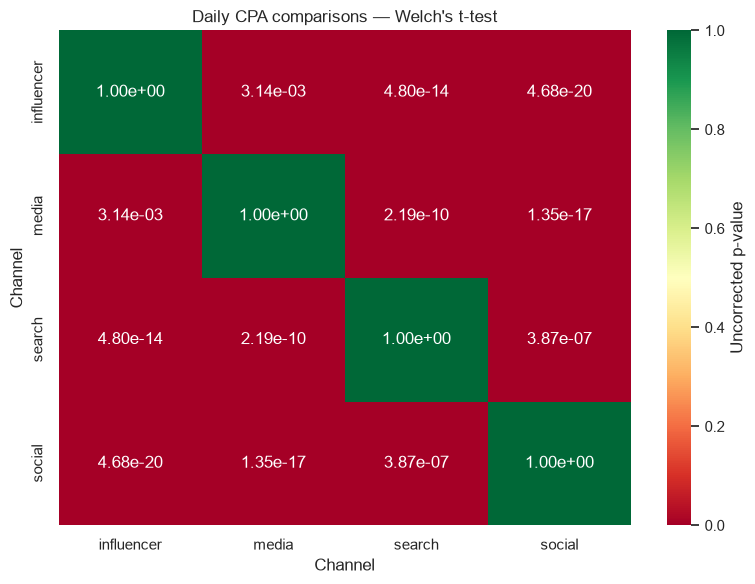

In [8]:
# TODO: heatmap of CPA p-values (channels x channels)
# Symmetric matrix of uncorrected CPA p-values
groups = sorted(paid["channel"].unique())
p_matrix = pd.DataFrame(1.0, index=groups, columns=groups)

for _, row in cpa_res.iterrows():
    a, b = row["group_a"], row["group_b"]
    p_matrix.loc[a, b] = row["p_value"]
    p_matrix.loc[b, a] = row["p_value"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    p_matrix,
    annot=True,
    fmt=".2e",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Uncorrected p-value"}
)
plt.title("Daily CPA comparisons — Welch's t-test")
plt.xlabel("Channel")
plt.ylabel("Channel")
plt.tight_layout()
plt.savefig(OUT / "metric_comparison_heatmap.png", dpi=150)
plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?**
All six channel pairs have different mean daily CPA values at
the uncorrected 0.05 level. All CPA effect sizes are large.

All six daily conversion rate comparisons are also significant
before correction. Multiple comparisons corrections are still pending.

The tests follow the lab's Welch approach. Channels share the
same dates, so common daily effects may affect the independence
assumption. These results do not prove causation.

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [9]:
# TODO: totals per channel
# Aggregate conversion and click counts
conv = df.groupby("channel")[["conversions", "clicks"]].sum()
conv["non_conversions"] = conv["clicks"] - conv["conversions"]
conv["conv_rate"] = conv["conversions"] / conv["clicks"]

assert (conv["non_conversions"] >= 0).all()

display(conv)

rows = []

for a, b in combinations(sorted(conv.index), 2):
    table = [
        [int(conv.loc[a, "conversions"]),
         int(conv.loc[a, "non_conversions"])],
        [int(conv.loc[b, "conversions"]),
         int(conv.loc[b, "non_conversions"])],
    ]

    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    rate_a = conv.loc[a, "conv_rate"]
    rate_b = conv.loc[b, "conv_rate"]
    diff = rate_b - rate_a

    rows.append({
        "group_a": a,
        "group_b": b,
        "conversions_a": int(conv.loc[a, "conversions"]),
        "clicks_a": int(conv.loc[a, "clicks"]),
        "conversions_b": int(conv.loc[b, "conversions"]),
        "clicks_b": int(conv.loc[b, "clicks"]),
        "rate_a": rate_a,
        "rate_b": rate_b,
        "diff_pp": diff * 100,
        "pct_diff": 100 * diff / rate_a,
        "odds_ratio": odds_ratio,
        "p_value": p,
        "significant": p < ALPHA,
    })

fisher_res = pd.DataFrame(rows)
fisher_res.to_csv(OUT / "fisher_results.csv", index=False)
conv.to_csv(OUT / "conversion_counts.csv")

print(
    f"Fisher: {len(fisher_res)} comparisons, "
    f"{fisher_res['significant'].sum()} significant before correction"
)
display(fisher_res)

,conversions,clicks,non_conversions,conv_rate
channel,,,,
influencer,3014,749973,746959,0.004019
media,1566,420003,418437,0.003729
search,828,330054,329226,0.002509
social,2635,1499889,1497254,0.001757


Fisher: 6 comparisons, 6 significant before correction


,group_a,group_b,conversions_a,clicks_a,conversions_b,clicks_b,rate_a,rate_b,diff_pp,pct_diff,odds_ratio,p_value,significant
0,influencer,media,3014,749973,1566,420003,0.004019,0.003729,-0.029027,-7.222697,1.078164,1.606020e-02,True
1,influencer,search,3014,749973,828,330054,0.004019,0.002509,-0.151013,-37.576557,1.604391,4.715446e-36,True
2,influencer,social,3014,749973,2635,1499889,0.004019,0.001757,-0.226201,-56.285665,2.292775,7.071416e-210,True
3,media,search,1566,420003,828,330054,0.003729,0.002509,-0.121986,-32.716903,1.488077,6.057999e-21,True
4,media,social,1566,420003,2635,1499889,0.003729,0.001757,-0.197175,-52.882511,2.126555,1.274586e-113,True
5,search,social,828,330054,2635,1499889,0.002509,0.001757,-0.075188,-29.971284,1.429062,4.269766e-18,True


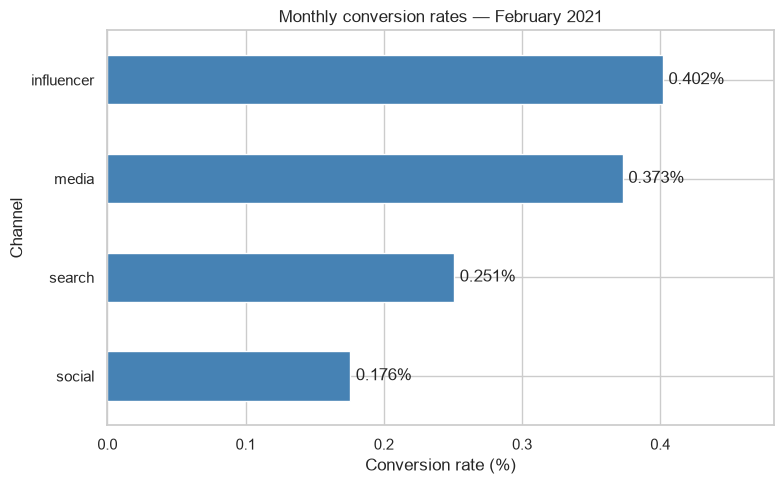

,group_a,group_b,p_value_welch,significant_welch,p_value_fisher,significant_fisher,agreement
0,influencer,media,3.591885e-02,True,1.606020e-02,True,True
1,influencer,search,1.002563e-08,True,4.715446e-36,True,True
2,influencer,social,3.208876e-13,True,7.071416e-210,True,True
3,media,search,5.402762e-03,True,6.057999e-21,True,True
4,media,social,2.720737e-05,True,1.274586e-113,True,True
5,search,social,1.844894e-02,True,4.269766e-18,True,True


Pairs with different significance decisions: 0


In [10]:
# TODO: horizontal bar chart of conversion rates, sorted, with % labels (plt.bar_label)
# Plot monthly conversion rates
rates = (conv["conv_rate"] * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
rates.plot.barh(ax=ax, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.3f%%", padding=4)
ax.set_xlabel("Conversion rate (%)")
ax.set_ylabel("Channel")
ax.set_title("Monthly conversion rates — February 2021")
ax.set_xlim(0, rates.max() * 1.2)

plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=150)
plt.show()

# Compare uncorrected significance decisions
test_comparison = cvr_t_res[
    ["group_a", "group_b", "p_value", "significant"]
].merge(
    fisher_res[["group_a", "group_b", "p_value", "significant"]],
    on=["group_a", "group_b"],
    suffixes=("_welch", "_fisher")
)

test_comparison["agreement"] = (
    test_comparison["significant_welch"]
    == test_comparison["significant_fisher"]
)

display(test_comparison)
print(
    "Pairs with different significance decisions:",
    (~test_comparison["agreement"]).sum()
)

test_comparison.to_csv(
    OUT / "conversion_test_comparison.csv", index=False
)

**✍️ Answer:**
1. All six channel pairs have significant conversion rate
   differences before multiple comparisons correction.
2. Influencer has the highest monthly conversion rate (0.402%),
   followed by media (0.373%), search (0.251%) and social (0.176%).
   Statistical significance alone does not show business value.
   For example, influencer and media differ by only 0.029
   percentage points.
3. Fisher and Welch agree on all six uncorrected decisions.
   Their p-values differ because Welch compares daily rates,
   while Fisher uses total conversion and click counts.
   Fisher assumes independent binary outcomes, which cannot
   be fully checked with this aggregated dataset.

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [11]:
families = {
    "CPA (t-test)": cpa_res,
    "Conv. rate (t-test)": cvr_t_res,
    "Conv. rate (Fisher)": fisher_res,
}

total_tests = sum(len(res) for res in families.values())
print("Total tests:", total_tests)
print(
    "Expected false positives if all null hypotheses are true:",
    total_tests * ALPHA
)

rows = []

for name, res in families.items():
    m = len(res)
    alpha_bonferroni = ALPHA / m

    res["p_value_bonferroni"] = np.minimum(
        res["p_value"] * m, 1.0
    )
    res["significant_bonferroni"] = (
        res["p_value"] < alpha_bonferroni
    )
    res["p_value_fdr"] = false_discovery_control(
        res["p_value"].to_numpy(), method="bh"
    )
    res["significant_fdr"] = res["p_value_fdr"] < ALPHA

    rows.append({
        "family": name,
        "tests": m,
        "Bonferroni alpha": alpha_bonferroni,
        "uncorrected": int(res["significant"].sum()),
        "Bonferroni": int(res["significant_bonferroni"].sum()),
        "BH-FDR": int(res["significant_fdr"].sum()),
    })

correction_summary = pd.DataFrame(rows).set_index("family")
display(correction_summary)

correction_summary.to_csv(OUT / "correction_summary.csv")
cpa_res.to_csv(OUT / "cpa_ttests.csv", index=False)
cvr_t_res.to_csv(OUT / "conversion_rate_ttests.csv", index=False)
fisher_res.to_csv(OUT / "fisher_results.csv", index=False)

Total tests: 18
Expected false positives if all null hypotheses are true: 0.9


,tests,Bonferroni alpha,uncorrected,Bonferroni,BH-FDR
family,,,,,
CPA (t-test),6,0.008333,6,6,6
Conv. rate (t-test),6,0.008333,6,4,6
Conv. rate (Fisher),6,0.008333,6,5,6



CPA (t-test)

Lost significance with Bonferroni: 0

Lost significance with BH-FDR: 0

Conv. rate (t-test)

Lost significance with Bonferroni: 2


,group_a,group_b,p_value,p_value_bonferroni,p_value_fdr
0,influencer,media,0.035919,0.215513,0.035919
5,search,social,0.018449,0.110694,0.022139



Lost significance with BH-FDR: 0

Conv. rate (Fisher)

Lost significance with Bonferroni: 1


,group_a,group_b,p_value,p_value_bonferroni,p_value_fdr
0,influencer,media,0.01606,0.096361,0.01606



Lost significance with BH-FDR: 0


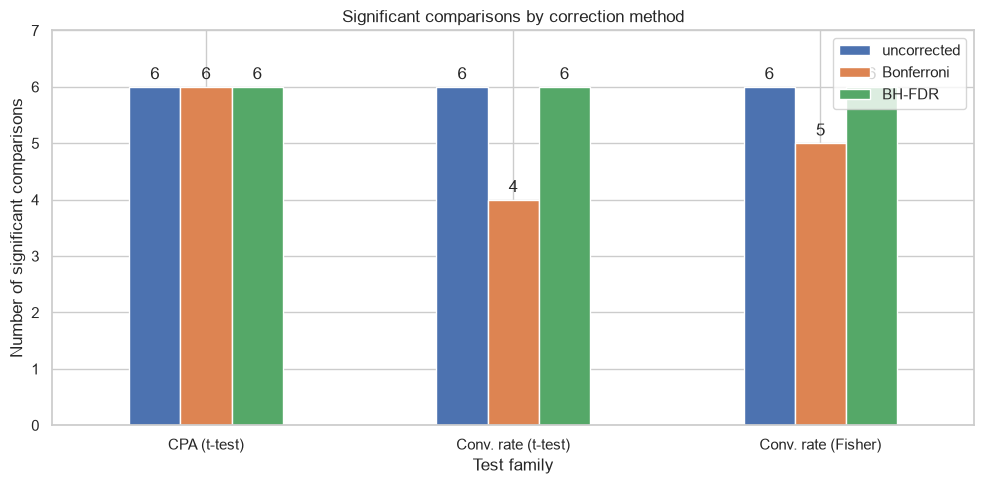

In [12]:
# TODO: which comparisons lose significance after each correction? Print them.
# Show comparisons that lose significance after correction
for name, res in families.items():
    print(f"\n{name}")

    for flag, label in [
        ("significant_bonferroni", "Bonferroni"),
        ("significant_fdr", "BH-FDR"),
    ]:
        lost = res.loc[
            res["significant"] & ~res[flag],
            ["group_a", "group_b", "p_value",
             "p_value_bonferroni", "p_value_fdr"]
        ]

        print(f"\nLost significance with {label}: {len(lost)}")
        if not lost.empty:
            display(lost)

# Compare correction methods
ax = correction_summary[
    ["uncorrected", "Bonferroni", "BH-FDR"]
].plot.bar(figsize=(10, 5), rot=0)

ax.set_title("Significant comparisons by correction method")
ax.set_xlabel("Test family")
ax.set_ylabel("Number of significant comparisons")
ax.set_ylim(0, 7)
ax.set_yticks(range(8))

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=150)
plt.show()

**✍️ Answer:**
1. Bonferroni reduced significant comparisons from 18 to 15:
   two daily conversion rate comparisons and one Fisher comparison.
   BH-FDR kept all 18. Losing significance does not prove that a
   result was a false positive.
2. Bonferroni is a cautious choice for budget decisions because
   a false winner can lead to wasted spending. BH is useful for
   exploration. Corrections were applied separately to each
   family of six tests, not jointly across all 18 tests.
3. All CPA comparisons remain significant with both corrections.
   However, conversion evidence for influencer versus media is
   weaker under Bonferroni. Budget changes should also consider
   ROAS, effect sizes, uncertainty and channel capacity.

## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

Base CPA: 3694.55
Simulation alpha: 0.05


effect_size_pct,5.0,10.0,15.0,20.0
n_days,,,,
28,0.193,0.669,0.958,0.997
30,0.242,0.716,0.977,0.998
60,0.438,0.959,0.999,1.000
90,0.600,0.991,1.000,1.000
120,0.715,0.998,1.000,1.000
180,0.895,1.000,1.000,1.000


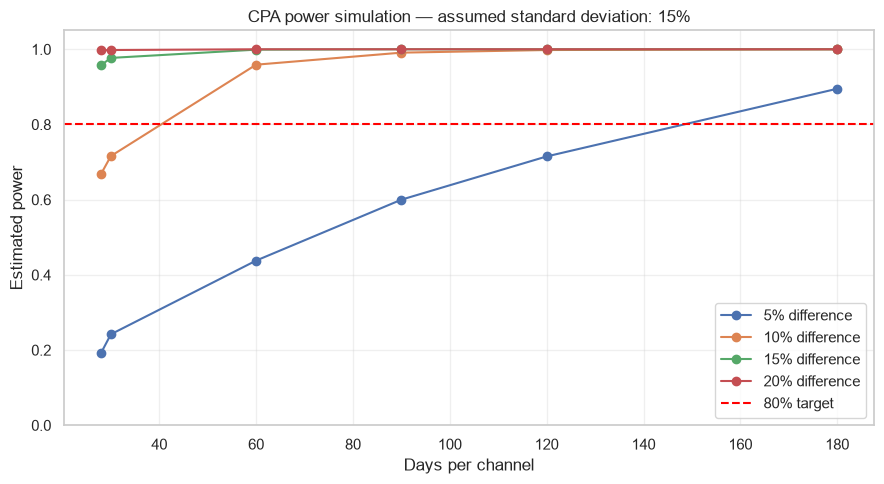

In [13]:
def empirical_power_cpa(
    true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05
):
    a = rng.normal(
        base_cpa, base_cpa * 0.15, size=(n_sim, n_days)
    )
    b = rng.normal(
        base_cpa * (1 + true_diff_pct),
        base_cpa * 0.15,
        size=(n_sim, n_days)
    )

    a = np.maximum(a, base_cpa * 0.5)
    b = np.maximum(b, base_cpa * 0.5)

    _, p_values = stats.ttest_ind(
        b, a, axis=1, equal_var=False
    )
    return np.mean(p_values < alpha)


# Reset the random generator for reproducible simulations
rng = np.random.default_rng(42)

BASE_CPA = float(agg["CPA"].median())
effects = [0.05, 0.10, 0.15, 0.20]
days = [28, 30, 60, 90, 120, 180]

power_df = pd.DataFrame([
    {
        "effect_size_pct": effect * 100,
        "n_days": n,
        "power": empirical_power_cpa(effect, BASE_CPA, n),
    }
    for effect in effects
    for n in days
])

print("Base CPA:", round(BASE_CPA, 2))
print("Simulation alpha:", ALPHA)
display(
    power_df.pivot(
        index="n_days", columns="effect_size_pct", values="power"
    ).round(3)
)

fig, ax = plt.subplots(figsize=(9, 5))

for effect, subset in power_df.groupby("effect_size_pct"):
    ax.plot(
        subset["n_days"], subset["power"],
        marker="o", label=f"{effect:.0f}% difference"
    )

ax.axhline(
    0.80, color="red", linestyle="--", label="80% target"
)
ax.set(
    xlabel="Days per channel",
    ylabel="Estimated power",
    title="CPA power simulation — assumed standard deviation: 15%",
    ylim=(0, 1.05)
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "power_analysis_cpa.png", dpi=150)
plt.show()

power_df.to_csv(OUT / "power_results.csv", index=False)

In [14]:
# TODO: minimum days for 80% power, per effect size. Is our data enough? ("sufficient" / "insufficient")
# TODO: for each CPA pair significant after BH: observed % difference (smaller mean = baseline),
#       power with your number of days, and days needed for 80% if power < 0.8
# Smallest TESTED sample size reaching 80% power
planning_rows = []

for effect in effects:
    subset = power_df[
        power_df["effect_size_pct"] == effect * 100
    ].sort_values("n_days")

    sufficient = subset[subset["power"] >= 0.80]
    min_tested = (
        int(sufficient["n_days"].min())
        if not sufficient.empty else np.nan
    )

    current_power = float(
        subset.loc[subset["n_days"] == 28, "power"].iloc[0]
    )

    planning_rows.append({
        "effect_size_pct": effect * 100,
        "smallest_tested_days_for_80pct": min_tested,
        "power_at_28_days": current_power,
        "status_at_28_days": (
            "sufficient" if current_power >= 0.80
            else "insufficient"
        ),
    })

sample_size_plan = pd.DataFrame(planning_rows)
display(sample_size_plan)
sample_size_plan.to_csv(
    OUT / "sample_size_plan.csv", index=False
)

# Scenario analysis using observed CPA gaps
# This is not independent confirmation of the observed findings.
rng = np.random.default_rng(43)
pair_rows = []

for _, row in cpa_res[cpa_res["significant_fdr"]].iterrows():
    baseline = min(row["mean_a"], row["mean_b"])
    gap_pct = abs(row["mean_b"] - row["mean_a"]) / baseline

    # Use the smaller valid sample size: 27 or 28 days
    current_n = min(int(row["n_a"]), int(row["n_b"]))
    power_now = empirical_power_cpa(
        gap_pct, baseline, current_n
    )

    tested_sizes = sorted(set([current_n] + days))
    first_sufficient = np.nan

    if power_now >= 0.80:
        first_sufficient = current_n
    else:
        for n in tested_sizes:
            if n <= current_n:
                continue
            if empirical_power_cpa(gap_pct, baseline, n) >= 0.80:
                first_sufficient = n
                break

    pair_rows.append({
        "group_a": row["group_a"],
        "group_b": row["group_b"],
        "observed_gap_pct": gap_pct * 100,
        "days_per_group_used": current_n,
        "scenario_power": power_now,
        "smallest_tested_days_for_80pct": first_sufficient,
    })

pair_power = pd.DataFrame(pair_rows)
display(pair_power.round(3))
pair_power.to_csv(OUT / "cpa_pair_power.csv", index=False)

,effect_size_pct,smallest_tested_days_for_80pct,power_at_28_days,status_at_28_days
0,5.0,180,0.193,insufficient
1,10.0,60,0.669,insufficient
2,15.0,28,0.958,sufficient
3,20.0,28,0.997,sufficient


,group_a,group_b,observed_gap_pct,days_per_group_used,scenario_power,smallest_tested_days_for_80pct
0,influencer,media,13.086,27,0.883,27
1,influencer,search,55.034,27,1.000,27
2,influencer,social,93.006,28,1.000,28
3,media,search,37.094,27,1.000,27
4,media,social,70.672,27,1.000,27
5,search,social,24.492,27,1.000,27


**✍️ Answer:**
1. With 28 days per channel, simulated power is 95.8% for a
   15% CPA difference and 99.7% for a 20% difference.
   Power is below 80% for differences of 5% and 10%.
2. For a 5% difference, 180 days is the smallest tested sample
   size reaching 80% power. This is not the exact minimum.
3. All CPA pairs were significant after correction. However,
   this does not mean that 28 days can detect smaller differences.
   A non-significant result would not prove equal performance.

These simulations assume independent daily observations,
normally distributed CPA before clipping, a standard deviation
of 15% of baseline CPA, and an uncorrected alpha of 0.05.
The observed-gap scenarios are not independent confirmation
of the findings. Power estimates may differ under other assumptions.

## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [15]:
# TODO: summary of significant findings (use the BH-corrected results)
#  - CPA: which channel is cheaper, by how much ($), adjusted p-value, Cohen's d
#  - Conversion rate: which channel is higher, by how many points, adjusted p-value
print("Daily CPA findings — BH correction")
for _, row in cpa_res[cpa_res["significant_fdr"]].iterrows():
    cheaper = (
        row["group_a"] if row["mean_a"] < row["mean_b"]
        else row["group_b"]
    )
    print(
        f"{row['group_a']} vs {row['group_b']}: "
        f"{cheaper} has lower mean daily CPA by "
        f"{abs(row['diff']):,.2f} dataset currency units; "
        f"BH p={row['p_value_fdr']:.3e}; "
        f"Cohen's d={row['cohens_d']:.3f}."
    )

print("\nMonthly conversion findings — Fisher, BH correction")
for _, row in fisher_res[fisher_res["significant_fdr"]].iterrows():
    higher = (
        row["group_a"] if row["rate_a"] > row["rate_b"]
        else row["group_b"]
    )
    print(
        f"{row['group_a']} vs {row['group_b']}: "
        f"{higher} has a higher conversion rate by "
        f"{abs(row['diff_pp']):.4f} percentage points; "
        f"BH p={row['p_value_fdr']:.3e}; "
        f"Bonferroni significant={row['significant_bonferroni']}."
    )

Daily CPA findings — BH correction
influencer vs media: influencer has lower mean daily CPA by 355.44 dataset currency units; BH p=3.136e-03; Cohen's d=0.835.
influencer vs search: influencer has lower mean daily CPA by 1,494.81 dataset currency units; BH p=9.599e-14; Cohen's d=2.871.
influencer vs social: influencer has lower mean daily CPA by 2,526.18 dataset currency units; BH p=2.808e-19; Cohen's d=4.296.
media vs search: media has lower mean daily CPA by 1,139.38 dataset currency units; BH p=3.289e-10; Cohen's d=2.191.
media vs social: media has lower mean daily CPA by 2,170.75 dataset currency units; BH p=4.038e-17; Cohen's d=3.696.
search vs social: search has lower mean daily CPA by 1,031.37 dataset currency units; BH p=4.640e-07; Cohen's d=1.564.

Monthly conversion findings — Fisher, BH correction
influencer vs media: influencer has a higher conversion rate by 0.0290 percentage points; BH p=1.606e-02; Bonferroni significant=False.
influencer vs search: influencer has a higher

In [16]:
def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    values = np.asarray(data, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    samples = rng.choice(
        values,
        size=(n_bootstrap, len(values)),
        replace=True
    )
    means = samples.mean(axis=1)
    tail = (1 - ci_level) / 2

    return tuple(
        np.quantile(means, [tail, 1 - tail])
    )


rng = np.random.default_rng(44)
ci_rows = []

for channel in sorted(df["channel"].unique()):
    values = df.loc[df["channel"] == channel, "CPA"].dropna()
    low, high = bootstrap_ci(values)

    ci_rows.append({
        "channel": channel,
        "valid_days": len(values),
        "mean_daily_CPA": values.mean(),
        "CI_95_low": low,
        "CI_95_high": high,
    })

cpa_ci = pd.DataFrame(ci_rows)
display(cpa_ci.round(2))

cpa_ci.to_csv(OUT / "cpa_confidence_intervals.csv", index=False)

,channel,valid_days,mean_daily_CPA,CI_95_low,CI_95_high
0,influencer,28,2716.16,2560.70,2847.84
1,media,27,3071.59,2904.57,3223.27
2,search,27,4210.97,4012.07,4484.91
3,social,28,5242.34,5001.01,5498.56


In [17]:
# Rank monthly metrics: higher rank means better performance
allocation = agg.loc[
    (agg["cost"] > 0)
    & agg["CPA"].notna()
    & agg["ROAS"].notna(),
    ["CPA", "ROAS"]
].copy()

allocation["CPA_rank"] = allocation["CPA"].rank(
    ascending=False, method="average"
)
allocation["ROAS_rank"] = allocation["ROAS"].rank(
    ascending=True, method="average"
)
allocation["composite_score"] = (
    0.5 * allocation["CPA_rank"]
    + 0.5 * allocation["ROAS_rank"]
)

# Find proportional shares subject to minimum and maximum limits
scores = allocation["composite_score"].to_numpy()
min_share, max_share = 0.05, 0.35
n_channels = len(scores)

assert n_channels * min_share <= 1 <= n_channels * max_share

low, high = 0.0, 1.0
while np.clip(high * scores, min_share, max_share).sum() < 1:
    high *= 2

for _ in range(100):
    scale = (low + high) / 2
    shares = np.clip(scale * scores, min_share, max_share)

    if shares.sum() < 1:
        low = scale
    else:
        high = scale

shares = np.clip(
    ((low + high) / 2) * scores, min_share, max_share
)

BUDGET_USD = 500_000
allocation["allocation_pct"] = shares * 100
allocation["allocation_USD"] = shares * BUDGET_USD

allocation = allocation.sort_values(
    "composite_score", ascending=False
)

assert np.isclose(allocation["allocation_USD"].sum(), BUDGET_USD)
assert allocation["allocation_pct"].between(
    5 - 1e-8, 35 + 1e-8
).all()

display(allocation.round(2))
print("Total allocation (USD):", allocation["allocation_USD"].sum())

allocation.to_csv(OUT / "budget_allocation.csv")

,CPA,ROAS,CPA_rank,ROAS_rank,composite_score,allocation_pct,allocation_USD
channel,,,,,,,
influencer,2755.58,2.54,4.0,4.0,4.0,35.00,175000.00
media,3209.88,1.22,3.0,3.0,3.0,32.50,162500.00
search,4179.23,1.07,2.0,2.0,2.0,21.67,108333.33
social,5236.62,0.86,1.0,1.0,1.0,10.83,54166.67


Total allocation (USD): 500000.00000000006


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

In [18]:
# TODO: write the executive memo as Markdown and save it
# Build Markdown tables without additional dependencies
def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend(
        "| " + " | ".join(str(value) for value in row) + " |"
        for row in rows
    )
    return "\n".join(lines)


budget_table = markdown_table(
    ["Channel", "Budget share", "Budget (USD)"],
    [
        [channel,
         f"{row['allocation_pct']:.2f}%",
         f"{row['allocation_USD']:,.2f}"]
        for channel, row in allocation.iterrows()
    ]
)

ci_table = markdown_table(
    ["Channel", "Valid days", "Mean daily CPA", "95% interval"],
    [
        [row["channel"],
         int(row["valid_days"]),
         f"{row['mean_daily_CPA']:,.2f}",
         f"{row['CI_95_low']:,.2f}–{row['CI_95_high']:,.2f}"]
        for _, row in cpa_ci.iterrows()
    ]
)

memo = f"""# Executive memo — Marketing budget allocation

**To:** CMO  
**From:** Sandra  
**Date:** 23 November 2026  
**Dataset:** Digital Marketing Metrics & KPIs to Measure  
**Source:** https://www.kaggle.com/datasets/sinderpreet/analyze-the-marketing-spending  
**Period:** 1–28 February 2021

## Executive summary

Influencer has the lowest monthly CPA and the highest ROAS.
Social has a ROAS below 1, so its attributed revenue is lower
than its advertising cost.

The table below is a starting budget scenario for the lab.
It is not a proven optimal allocation or a forecast.
Test changes before using this plan for a real business.

## Key findings

- The original data contains 308 campaign-day records.
  We grouped them into four categories with 28 days each.
- Monthly CPA is 2,755.58 for influencer, 3,209.88 for media,
  4,179.23 for search and 5,236.62 for social.
  These amounts use the dataset's unverified currency.
- ROAS is 2.54 for influencer, 1.22 for media,
  1.07 for search and 0.86 for social.
- All six daily CPA comparisons remain significant after
  Bonferroni and BH correction. All CPA effect sizes are large.
- All six conversion comparisons remain significant with BH
  for both Welch and Fisher.
- Bonferroni keeps four Welch conversion comparisons and five
  Fisher comparisons. Influencer versus media does not remain
  significant with Bonferroni in either conversion test.
- The monthly conversion gap between influencer and media is
  only about 0.029 percentage points. Statistical significance
  alone does not show business value.

## Data adequacy

At 28 days, simulated power is 19.3% for a 5% CPA difference,
66.9% for 10%, 95.8% for 15% and 99.7% for 20%.

For a 5% difference, 180 days is the smallest tested sample size
reaching 80% power. For 10%, it is 60 days.
These are tested sizes, not exact minimum requirements.

The simulation assumes independent days, a standard deviation
of 15% of baseline CPA, and uncorrected alpha of 0.05.
Planning with Bonferroni would require a separate power calculation.
Scenarios using observed gaps do not independently confirm findings.

## Recommendations

{budget_table}

Total proposed budget: **500,000 USD**.

The score uses monthly CPA and ROAS with equal weights.
Higher scores receive more budget, with a 5% minimum and
35% maximum per category. Both metrics give the same ranking.

Prioritize controlled tests in influencer and media.
Review social campaigns before increasing their budget.
Keep search under review because its ROAS is only slightly above 1.

The ranking does not measure uncertainty, future capacity or
returns from additional spending. The 35% cap is a planning rule,
not evidence that a channel can absorb that amount.
The plan retains some social budget for testing; this does not
show that social is profitable.

## Confidence intervals

The following intervals describe mean daily CPA in dataset
currency units, using 1,000 bootstrap samples.

{ci_table}

These means differ from monthly CPA, which is total cost divided
by total conversions.

## Statistical caveats

- The file was downloaded from Kaggle. Its original business
  source, real or synthetic status, currency and attribution rules
  were not independently verified.
- Data covers only one month in 2021. It does not establish
  current performance or seasonal patterns.
- Channel categories contain different campaign mixes.
  Observational differences do not prove causation.
- Welch follows the lab template. Channels share dates, so
  common daily effects may affect independence.
- Fisher assumes independent clicks with binary conversion
  outcomes. Repeated users or multiple orders cannot be checked.
- Corrections apply separately to three families of six tests.
  They do not jointly control error across all 18 tests.
  BH is reported for exploration; Bonferroni provides a more
  cautious comparison. No correction makes a result certain.
- Media and search each have one day with zero conversions.
  Daily CPA analysis excludes those undefined ratios.
  Monthly CPA includes all costs. The exclusion may affect
  daily mean comparisons.
- Bootstrap intervals are individual 95% intervals, without
  multiple-comparison adjustment or time-dependence adjustment.
- Revenue minus advertising cost is not net profit.
  Product, delivery and other business costs are missing.
- The USD allocation is a lab scenario. Historical amounts
  were not converted to USD, and future returns are not predicted.

## Next steps

1. Verify source, currency, tracking and conversion definitions.
2. Define a useful business improvement before a new test.
3. Plan sample size using realistic variability and the chosen
   correction, then run a fixed-size controlled test.
4. Check channel capacity, attribution and full costs.
5. Monitor CPA, ROAS and conversion quality during any rollout.
"""

(OUT / "executive_memo.md").write_text(memo, encoding="utf-8")
display(Markdown(memo))

# Executive memo — Marketing budget allocation

**To:** CMO  
**From:** Sandra  
**Date:** 23 November 2026  
**Dataset:** Digital Marketing Metrics & KPIs to Measure  
**Source:** https://www.kaggle.com/datasets/sinderpreet/analyze-the-marketing-spending  
**Period:** 1–28 February 2021

## Executive summary

Influencer has the lowest monthly CPA and the highest ROAS.
Social has a ROAS below 1, so its attributed revenue is lower
than its advertising cost.

The table below is a starting budget scenario for the lab.
It is not a proven optimal allocation or a forecast.
Test changes before using this plan for a real business.

## Key findings

- The original data contains 308 campaign-day records.
  We grouped them into four categories with 28 days each.
- Monthly CPA is 2,755.58 for influencer, 3,209.88 for media,
  4,179.23 for search and 5,236.62 for social.
  These amounts use the dataset's unverified currency.
- ROAS is 2.54 for influencer, 1.22 for media,
  1.07 for search and 0.86 for social.
- All six daily CPA comparisons remain significant after
  Bonferroni and BH correction. All CPA effect sizes are large.
- All six conversion comparisons remain significant with BH
  for both Welch and Fisher.
- Bonferroni keeps four Welch conversion comparisons and five
  Fisher comparisons. Influencer versus media does not remain
  significant with Bonferroni in either conversion test.
- The monthly conversion gap between influencer and media is
  only about 0.029 percentage points. Statistical significance
  alone does not show business value.

## Data adequacy

At 28 days, simulated power is 19.3% for a 5% CPA difference,
66.9% for 10%, 95.8% for 15% and 99.7% for 20%.

For a 5% difference, 180 days is the smallest tested sample size
reaching 80% power. For 10%, it is 60 days.
These are tested sizes, not exact minimum requirements.

The simulation assumes independent days, a standard deviation
of 15% of baseline CPA, and uncorrected alpha of 0.05.
Planning with Bonferroni would require a separate power calculation.
Scenarios using observed gaps do not independently confirm findings.

## Recommendations

| Channel | Budget share | Budget (USD) |
| --- | --- | --- |
| influencer | 35.00% | 175,000.00 |
| media | 32.50% | 162,500.00 |
| search | 21.67% | 108,333.33 |
| social | 10.83% | 54,166.67 |

Total proposed budget: **500,000 USD**.

The score uses monthly CPA and ROAS with equal weights.
Higher scores receive more budget, with a 5% minimum and
35% maximum per category. Both metrics give the same ranking.

Prioritize controlled tests in influencer and media.
Review social campaigns before increasing their budget.
Keep search under review because its ROAS is only slightly above 1.

The ranking does not measure uncertainty, future capacity or
returns from additional spending. The 35% cap is a planning rule,
not evidence that a channel can absorb that amount.
The plan retains some social budget for testing; this does not
show that social is profitable.

## Confidence intervals

The following intervals describe mean daily CPA in dataset
currency units, using 1,000 bootstrap samples.

| Channel | Valid days | Mean daily CPA | 95% interval |
| --- | --- | --- | --- |
| influencer | 28 | 2,716.16 | 2,560.70–2,847.84 |
| media | 27 | 3,071.59 | 2,904.57–3,223.27 |
| search | 27 | 4,210.97 | 4,012.07–4,484.91 |
| social | 28 | 5,242.34 | 5,001.01–5,498.56 |

These means differ from monthly CPA, which is total cost divided
by total conversions.

## Statistical caveats

- The file was downloaded from Kaggle. Its original business
  source, real or synthetic status, currency and attribution rules
  were not independently verified.
- Data covers only one month in 2021. It does not establish
  current performance or seasonal patterns.
- Channel categories contain different campaign mixes.
  Observational differences do not prove causation.
- Welch follows the lab template. Channels share dates, so
  common daily effects may affect independence.
- Fisher assumes independent clicks with binary conversion
  outcomes. Repeated users or multiple orders cannot be checked.
- Corrections apply separately to three families of six tests.
  They do not jointly control error across all 18 tests.
  BH is reported for exploration; Bonferroni provides a more
  cautious comparison. No correction makes a result certain.
- Media and search each have one day with zero conversions.
  Daily CPA analysis excludes those undefined ratios.
  Monthly CPA includes all costs. The exclusion may affect
  daily mean comparisons.
- Bootstrap intervals are individual 95% intervals, without
  multiple-comparison adjustment or time-dependence adjustment.
- Revenue minus advertising cost is not net profit.
  Product, delivery and other business costs are missing.
- The USD allocation is a lab scenario. Historical amounts
  were not converted to USD, and future returns are not predicted.

## Next steps

1. Verify source, currency, tracking and conversion definitions.
2. Define a useful business improvement before a new test.
3. Plan sample size using realistic variability and the chosen
   correction, then run a fixed-size controlled test.
4. Check channel capacity, attribution and full costs.
5. Monitor CPA, ROAS and conversion quality during any rollout.


## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results?
2. How did multiple-comparison correction change your conclusions?
3. What are the limits of this analysis?
4. How would you explain the findings to a non-technical CMO in one minute?

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`

In [19]:
# Verify submission files
required = [
    "README.md",
    "lab_proof.md",
    "Marketing.csv",
    "outputs/marketing_data.csv",
    "outputs/channel_summary.csv",
    "outputs/channel_variability.csv",
    "outputs/cpa_ttests.csv",
    "outputs/conversion_rate_ttests.csv",
    "outputs/conversion_counts.csv",
    "outputs/fisher_results.csv",
    "outputs/conversion_test_comparison.csv",
    "outputs/correction_summary.csv",
    "outputs/power_results.csv",
    "outputs/sample_size_plan.csv",
    "outputs/cpa_pair_power.csv",
    "outputs/cpa_confidence_intervals.csv",
    "outputs/budget_allocation.csv",
    "outputs/executive_memo.md",
    "outputs/group_metrics_overview.png",
    "outputs/group_distributions.png",
    "outputs/metric_comparison_heatmap.png",
    "outputs/rate_comparison.png",
    "outputs/correction_comparison.png",
    "outputs/power_analysis_cpa.png",
]

missing = [name for name in required if not Path(name).is_file()]

print("Required files checked:", len(required))
print("Missing files:", missing)

assert not missing, "Some submission files are missing."
assert np.isclose(allocation["allocation_USD"].sum(), 500_000)

print("Submission checks passed.")

Required files checked: 24
Missing files: []
Submission checks passed.
